# Practica de Visualización

Un dataset de NOAA está almacenado en el archivo `data/fb441e62df2d58994928907a91895ec62c2c42e6cd075c2700843b89.csv`. Este es el dataset que utilizaremos para la práctica.

Nota: Los datos para esta práctica forman parte de un dataset perteneciente a The data for this assignment comes from a subset of The National Centers for Environmental Information (NCEI) [Daily Global Historical Climatology Network](https://www1.ncdc.noaa.gov/pub/data/ghcn/daily/readme.txt) (GHCN-Daily). El GHCN-Daily se compone de registros climáticos diarios de miles de estaciones de la superficie terrestre en todo el mundo.

Cada fila en el archivo de datos corresponde a una sola observación.

Nos proporciona las siguientes variables:

- **id** : código de identificación de la estación
- **date** : fecha en formato YYYY-MM-DD (por ejemplo: 2012-01-24 = 24 de enero de 2012)
- **element** : indica el tipo de medición
    - **TMAX** : Temperatura máxima
    - **TMIN** : Temperatura mínima
- **value**: valor de la temperatura (en décimas de grados centígrados)

## Indicaciones

1. Lee la documentación y familiarícese con el conjunto de datos, luego escriba un código python que arroje un gráfico lineal de las temperaturas máximas y mínimas récord por día del año durante el período 2005-2014. El área entre las temperaturas máximas y mínimas récord de cada día debe estar sombreada.
2. Superponga una dispersión de los datos de 2015 para cualquier punto (máximos y mínimos) para los cuales se superó el récord de diez años (2005-2014) máximo o mínimo histórico en 2015.
3. Debes tener cuidado con los días bisiestos (es decir, el 29 de febrero), es totalmente razonable eliminar estos puntos del conjunto de datos para esta visualización.
4. ¡Haz que la imagen sea agradable! Considera problemas como leyendas, etiquetas y líneas en demasía.

Los datos proporcionados están cerca de **Ann Arbor, Michigan, Estados Unidos**.

In [70]:
import matplotlib.pyplot as plt
import pandas as pd

# Tu código a partir de aquí

In [71]:
import os

print(os.getcwd())

C:\Users\clari\PycharmProjects\ucu-pod01-datavisualization\notebooks


In [72]:
print(os.listdir())

['class-visualization.ipynb', 'practice.ipynb']


In [73]:
df = pd.read_csv(
    "../data/fb441e62df2d58994928907a91895ec62c2c42e6cd075c2700843b89.csv"
)

print(df.head())

            ID        Date Element  Data_Value
0  USW00094889  2014-11-12    TMAX          22
1  USC00208972  2009-04-29    TMIN          56
2  USC00200032  2008-05-26    TMAX         278
3  USC00205563  2005-11-11    TMAX         139
4  USC00200230  2014-02-27    TMAX        -106


In [74]:
#convertir la fecha a formato fecha
df["Date"] = pd.to_datetime(df["Date"])
print(df.dtypes)

ID                       str
Date          datetime64[us]
Element                  str
Data_Value             int64
dtype: object


In [75]:
#convertir la temperatura a grados celcius
df["Data_Value"] = df["Data_Value"] / 10
print(df.head())

            ID       Date Element  Data_Value
0  USW00094889 2014-11-12    TMAX         2.2
1  USC00208972 2009-04-29    TMIN         5.6
2  USC00200032 2008-05-26    TMAX        27.8
3  USC00205563 2005-11-11    TMAX        13.9
4  USC00200230 2014-02-27    TMAX       -10.6


In [76]:
#crear una columna con el año de cada temperatura para comparar 2014 con 2015
df["Year"] = df["Date"].dt.year
print(df.head())

            ID       Date Element  Data_Value  Year
0  USW00094889 2014-11-12    TMAX         2.2  2014
1  USC00208972 2009-04-29    TMIN         5.6  2009
2  USC00200032 2008-05-26    TMAX        27.8  2008
3  USC00205563 2005-11-11    TMAX        13.9  2005
4  USC00200230 2014-02-27    TMAX       -10.6  2014


In [77]:
#obtener columna con el mes y día para hacer la comparación
df["Day"] = df["Date"].dt.strftime("%m-%d") #obtener mes y día
print(df.head())

            ID       Date Element  Data_Value  Year    Day
0  USW00094889 2014-11-12    TMAX         2.2  2014  11-12
1  USC00208972 2009-04-29    TMIN         5.6  2009  04-29
2  USC00200032 2008-05-26    TMAX        27.8  2008  05-26
3  USC00205563 2005-11-11    TMAX        13.9  2005  11-11
4  USC00200230 2014-02-27    TMAX       -10.6  2014  02-27


In [78]:
#eliminar 29 de febrero
df = df[df["Day"] != "02-29"]
print(df.shape) # muestra cuantas filas y columnas tiene df

(165002, 6)


In [79]:
#filtrar registros 2005-2014
historicos = df[(df["Year"] >= 2005) & (df["Year"] <= 2014)]
print(historicos.head())

            ID       Date Element  Data_Value  Year    Day
0  USW00094889 2014-11-12    TMAX         2.2  2014  11-12
1  USC00208972 2009-04-29    TMIN         5.6  2009  04-29
2  USC00200032 2008-05-26    TMAX        27.8  2008  05-26
3  USC00205563 2005-11-11    TMAX        13.9  2005  11-11
4  USC00200230 2014-02-27    TMAX       -10.6  2014  02-27


In [80]:
#separar temperaturas máx y mín
maximas = historicos[historicos["Element"] == "TMAX"]
print(maximas.head())

minimas = historicos[historicos["Element"] == "TMIN"]
print(minimas.head())

            ID       Date Element  Data_Value  Year    Day
0  USW00094889 2014-11-12    TMAX         2.2  2014  11-12
2  USC00200032 2008-05-26    TMAX        27.8  2008  05-26
3  USC00205563 2005-11-11    TMAX        13.9  2005  11-11
4  USC00200230 2014-02-27    TMAX       -10.6  2014  02-27
5  USW00014833 2010-10-01    TMAX        19.4  2010  10-01
             ID       Date Element  Data_Value  Year    Day
1   USC00208972 2009-04-29    TMIN         5.6  2009  04-29
6   USC00207308 2010-06-29    TMIN        14.4  2010  06-29
8   USW00004848 2007-12-14    TMIN        -1.6  2007  12-14
11  USC00205822 2008-05-29    TMIN         2.8  2008  05-29
12  USC00203712 2008-10-17    TMIN         1.7  2008  10-17


In [81]:
#temperatura max de cada día y temperatura min de cada día
record_max = maximas.groupby("Day")["Data_Value"].max()
print(record_max)
record_min = minimas.groupby("Day")["Data_Value"].min()
print(record_min)

Day
01-01    15.6
01-02    13.9
01-03    13.3
01-04    10.6
01-05    12.8
         ... 
12-27    18.9
12-28    19.4
12-29    12.8
12-30    11.7
12-31    13.9
Name: Data_Value, Length: 365, dtype: float64
Day
01-01   -16.0
01-02   -26.7
01-03   -26.7
01-04   -26.1
01-05   -15.0
         ... 
12-27   -13.8
12-28   -16.6
12-29   -15.0
12-30   -14.4
12-31   -15.0
Name: Data_Value, Length: 365, dtype: float64


In [82]:
#registros 2015
datos_2015 = df[df["Year"] == 2015]
print(datos_2015.head())

             ID       Date Element  Data_Value  Year    Day
19  USC00205563 2015-01-03    TMIN        -3.9  2015  01-03
30  USC00203712 2015-03-17    TMAX        18.9  2015  03-17
34  USC00200032 2015-06-06    TMIN        12.8  2015  06-06
46  USW00014833 2015-08-30    TMIN        17.8  2015  08-30
50  USC00202308 2015-08-30    TMIN        15.6  2015  08-30


In [83]:
#temperaturas minimas y maximas de 2015
max_2015 = datos_2015[datos_2015["Element"] == "TMAX"]
min_2015 = datos_2015[datos_2015["Element"] == "TMIN"]
print(max_2015.head())
print(min_2015.head())

              ID       Date Element  Data_Value  Year    Day
30   USC00203712 2015-03-17    TMAX        18.9  2015  03-17
51   USC00205563 2015-01-03    TMAX         2.2  2015  01-03
59   USC00202308 2015-08-30    TMAX        26.1  2015  08-30
126  USC00200032 2015-06-06    TMAX        23.3  2015  06-06
146  USC00208972 2015-04-09    TMAX         6.7  2015  04-09
             ID       Date Element  Data_Value  Year    Day
19  USC00205563 2015-01-03    TMIN        -3.9  2015  01-03
34  USC00200032 2015-06-06    TMIN        12.8  2015  06-06
46  USW00014833 2015-08-30    TMIN        17.8  2015  08-30
50  USC00202308 2015-08-30    TMIN        15.6  2015  08-30
72  USC00200230 2015-04-01    TMIN        -1.7  2015  04-01


In [84]:
#temperatura minima y maxima de 2015 por día
max_2015 = max_2015.groupby("Day")["Data_Value"].max()
min_2015 = min_2015.groupby("Day")["Data_Value"].min()
print(max_2015.head())
print(min_2015.head())

Day
01-01    1.1
01-02    3.9
01-03    3.9
01-04    4.4
01-05    2.8
Name: Data_Value, dtype: float64
Day
01-01   -13.3
01-02   -12.2
01-03    -6.7
01-04    -8.8
01-05   -15.5
Name: Data_Value, dtype: float64


In [85]:
#records superados en 2015
supera_max = max_2015[max_2015 > record_max]
supera_min = min_2015[min_2015 < record_min]
print(supera_max.head())
print(supera_min.head())

Day
02-09     8.3
04-17    27.8
05-07    30.6
05-08    33.3
05-11    30.6
Name: Data_Value, dtype: float64
Day
01-05   -15.5
01-11   -20.0
02-03   -23.8
02-14   -23.9
02-15   -26.0
Name: Data_Value, dtype: float64


In [86]:
#fechas para el eje x
fechas = pd.to_datetime("2015-" + record_max.index)
print(fechas[:5])

DatetimeIndex(['2015-01-01', '2015-01-02', '2015-01-03', '2015-01-04',
               '2015-01-05'],
              dtype='datetime64[us]', name='Day', freq=None)


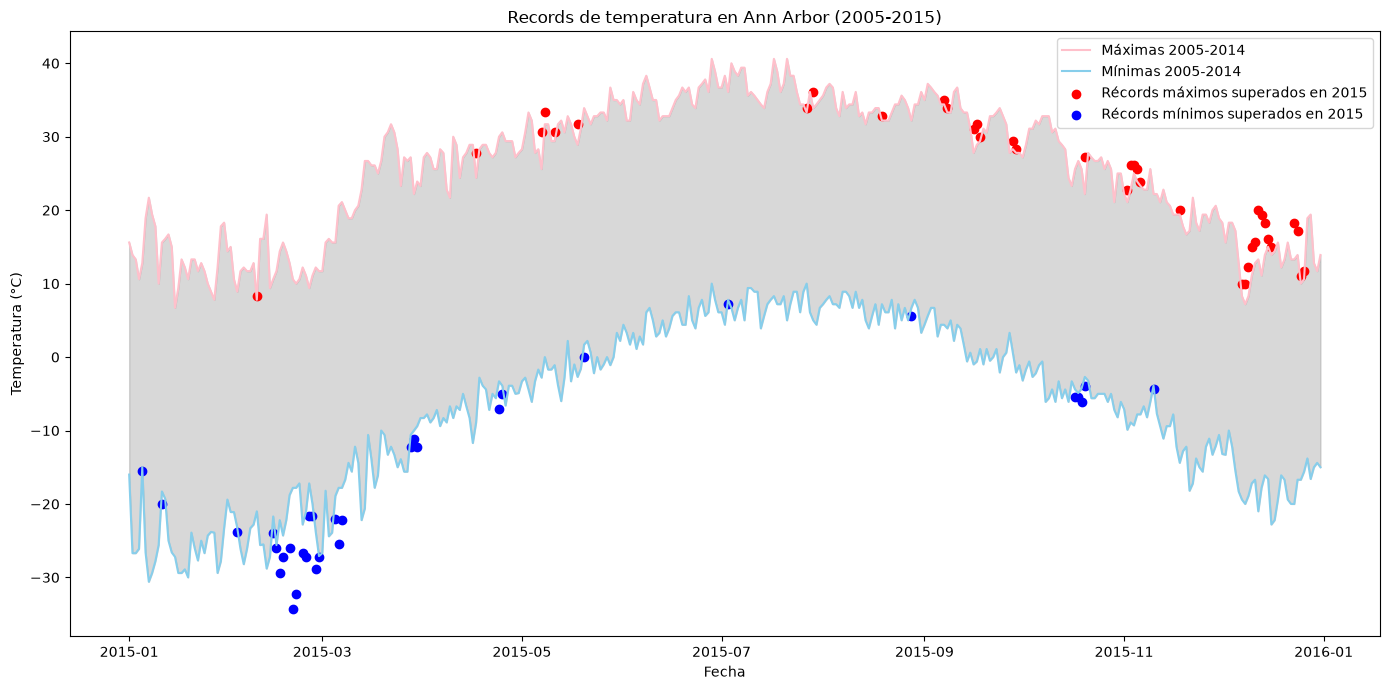

In [87]:
#grafico
plt.figure(figsize=(14, 7)) #tamaño del grafico
plt.plot(fechas, record_max, color="pink", label="Máximas 2005-2014") #dibujar temp max
plt.plot(fechas, record_min, color="skyblue", label="Mínimas 2005-2014") #dibujar temp min
plt.fill_between(fechas, record_min, record_max, color="gray", alpha=0.3) #pintar área entre lineas
plt.scatter(
    pd.to_datetime("2015-" + supera_max.index),
    supera_max,
    color="red",
    label="Récords máximos superados en 2015"
) #agregar records máx 2015
plt.scatter(
    pd.to_datetime("2015-" + supera_min.index),
    supera_min,
    color="blue",
    label="Récords mínimos superados en 2015"
) # agregar records mín 2015
plt.title("Records de temperatura en Ann Arbor (2005-2015)") #nombre del grafico
plt.xlabel("Fecha") #nombre eje x
plt.ylabel("Temperatura (°C)") #nombre eje y
plt.legend()
plt.tight_layout() #matplotlib ajusta automaticamente el grafico
plt.show() #mostrar el grafico